# Outlier CA phylogeny analysis, scaled up, with a non-replicator control

Repeats the border-versus-middle analysis of [`2026-05-11-hstrat-paper-outlier-plots.ipynb`](2026-05-11-hstrat-paper-outlier-plots.ipynb) with two changes.

1. **Larger run.** The outlier CA is run for $\sqrt{10}\times$ as many steps on a grid with $\sqrt{10}\times$ the side length. The pattern grows at constant speed, so this gives about $10\times$ the extant population (and so $10\times$ the phylogeny tips) of the reference run.
2. **Non-replicator control.** The same pipeline is applied to a second expanding CA, 3-4 Life (B34/S34), which grows from a small seed as a dense chaotic blob rather than by budding off discrete self-copying structures. It is run until its extant population matches the scaled-up outlier run.

Unlike the reference notebook, which downloads phylogenies generated on GPU by [`pylib/track_outlier.ipynb`](../pylib/track_outlier.ipynb), both CAs are run here, on CPU, using `pylib.track_ca_fast.FastCATracker`. That class fuses the CA update and hstrat marker inheritance into one compiled pass over live cells, with the same semantics as `pylib.track_ca.MultiTracker` driven with `dstream_S=64`, `dstream_bitwidth=1`, and `add_random_noise=True` (see its module docstring).


In [1]:
%load_ext watermark


In [2]:
import math
import os
import typing

from downstream import dstream
import matplotlib as mpl
import matplotlib.path
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import _auxlib as pfa
from phyloframe import legacy as pfl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from tqdm import tqdm

from pylib.track_ca_fast import (
    FastCATracker,
    decode_rule_table,
    make_lifelike_rule_table,
    parse_rle,
)
from pylib.tree import draw_scatter_tree


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [3]:
%watermark -diwmuv -iv


Last updated: 2026-11-27T06:25:30.799127+00:00

Python implementation: CPython
Python version       : 3.11.18
IPython version      : 7.31.1

Compiler    : GCC 11.4.0
OS          : Linux
Release     : 6.8.0-1070-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

matplotlib: 3.10.0
pandas    : 2.2.3
teeplot   : 1.4.2
phyloframe: 0.10.0
numpy     : 2.1.2
seaborn   : 0.13.2
downstream: 1.22.0
scipy     : 1.14.1

Watermark: 2.4.3



In [4]:
teeplot_subdir = os.environ.get(
    "NOTEBOOK_NAME", "2026-11-27-outlier-plots-scaled-control"
)
teeplot_subdir


'2026-11-27-outlier-plots-scaled-control'

In [5]:
pfa.seed_random(1)


## Parameters

The reference run took 15,000 steps on a 2,300 x 2,300 grid.
Analysis cutoffs, which the reference notebook gives as absolute times, are expressed here as fractions of run length so that they carry over to runs of other lengths.


In [6]:
REFERENCE_NUM_STEPS = 15_000
REFERENCE_GRID_SIZE = 2_300

SCALE = 10  # target increase in extant population size
LINEAR_SCALE = math.sqrt(SCALE)

# only nodes older than this fraction of the run enter the imbalance analysis
COLLESS_CUTOFF_FRAC = 13_504 / REFERENCE_NUM_STEPS
# only nodes older than this fraction of the run enter the branch length plot
DELTA_CUTOFF_FRAC = 12_000 / REFERENCE_NUM_STEPS

N_NULL_SAMPLES = 10_000  # random trees per null model


## Run CAs


In [7]:
def run_ca(
    rule: np.ndarray,
    seed_pattern: np.ndarray,
    *,
    grid_size: int,
    num_steps: int,
    desc: str,
    seed: int = 1,
) -> pd.DataFrame:
    # Grow `seed_pattern` from the grid center, and reconstruct the phylogeny
    # of the cells alive after `num_steps`.
    grid = np.zeros((grid_size, grid_size), dtype=np.uint8)
    h, w = seed_pattern.shape
    oy, ox = (grid_size - h) // 2, (grid_size - w) // 2
    grid[oy : oy + h, ox : ox + w] = seed_pattern

    tracker = FastCATracker(rule, grid, dstream.steady_algo, seed=seed)
    with tqdm(total=num_steps, desc=desc, mininterval=30) as progress:
        while tracker.t < num_steps:
            chunk = min(500, num_steps - tracker.t)
            tracker.step(chunk)
            progress.update(chunk)
            progress.set_postfix(alive=tracker.num_alive, refresh=False)

    df = tracker.reconstruct_phylogeny()
    # origin times are offset by -dstream_S, so the earliest wrap below zero
    df["origin_time"] = df["origin_time"].astype(np.int64).clip(lower=0)
    df.attrs["num_steps"] = num_steps
    df.attrs["seed_center"] = (oy + (h - 1) / 2, ox + (w - 1) / 2)
    return df


### Outlier CA

Same rule table and seed as the reference run.


In [8]:
OUTLIER_RULE = decode_rule_table(
    "ERETQB4eHWkQ7xD4eYZosBQZFixOBHmtFeehExrKVhURLRAqGxeIlSO1JYZP6DRi69rop7TQCkvWTIag7kAS8g",
)
OUTLIER_SEED = parse_rle("$bo$3o$2bo!")
OUTLIER_NUM_STEPS = round(REFERENCE_NUM_STEPS * LINEAR_SCALE)
OUTLIER_GRID_SIZE = 8 * math.ceil(REFERENCE_GRID_SIZE * LINEAR_SCALE / 8)
OUTLIER_NUM_STEPS, OUTLIER_GRID_SIZE


(47434, 7280)

In [9]:
phylos = {}
phylos["outlier"] = run_ca(
    OUTLIER_RULE,
    OUTLIER_SEED,
    grid_size=OUTLIER_GRID_SIZE,
    num_steps=OUTLIER_NUM_STEPS,
    desc="outlier",
)


outlier: 100%|██████████| 47434/47434 [07:43<00:00, 102.32it/s, alive=590110]
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(
2026-11-27 06:33:19 INFO     - worker collecting slice(0, 1000000, None)
2026-11-27 06:33:19 INFO     - worker exploding slice(0, 1000000, None)
2026-11-27 06:33:19 INFO     enter log_context_duration for dstream.dataframe.explode_lookup_unpacked (slice(0, 1000000, None))
2026-11-27 06:33:19 INFO     begin explode_lookup_unpacked
2026-11-27 06:33:19 INFO      - prepping data...
2026-11-27 06:33:19 INFO      - exploding dataframe...
2026-11-27 06:33:19 INFO      - unpacking hex strings...
2026-11-27 06:33:19 INFO      - looking up ingest times...
2026-11-27 06:33:25 INFO      - calculating argsort of 

### Non-replicator control CA

3-4 Life (B34/S34), seeded with a 24 x 24 random soup.
Its population grows quadratically, reaching the size of the reference outlier run after about 1,200 steps, so its run length is scaled from there.
The front advances faster than the outlier's, so the control reaches the same population in fewer steps.


In [10]:
CONTROL_RULE = make_lifelike_rule_table(birth=[3, 4], survive=[3, 4])
CONTROL_SEED = (np.random.default_rng(1).random((24, 24)) < 0.5).astype(
    np.uint8,
)
CONTROL_NUM_STEPS = round(1_200 * LINEAR_SCALE)
CONTROL_GRID_SIZE = 8 * math.ceil(0.55 * CONTROL_NUM_STEPS / 8)
CONTROL_NUM_STEPS, CONTROL_GRID_SIZE


(3795, 2088)

In [11]:
phylos["control"] = run_ca(
    CONTROL_RULE,
    CONTROL_SEED,
    grid_size=CONTROL_GRID_SIZE,
    num_steps=CONTROL_NUM_STEPS,
    desc="control",
)


control: 100%|██████████| 3795/3795 [00:11<00:00, 323.87it/s, alive=580456]
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(
2026-11-27 06:33:44 INFO     - worker collecting slice(0, 1000000, None)
2026-11-27 06:33:44 INFO     - worker exploding slice(0, 1000000, None)
2026-11-27 06:33:44 INFO     enter log_context_duration for dstream.dataframe.explode_lookup_unpacked (slice(0, 1000000, None))
2026-11-27 06:33:44 INFO     begin explode_lookup_unpacked
2026-11-27 06:33:44 INFO      - prepping data...
2026-11-27 06:33:44 INFO      - exploding dataframe...
2026-11-27 06:33:45 INFO      - unpacking hex strings...
2026-11-27 06:33:45 INFO      - looking up ingest times...
2026-11-27 06:33:49 INFO      - calculating argsort of in

In [12]:
pd.DataFrame(
    {
        name: {
            "num steps": df.attrs["num_steps"],
            "num extant cells": df["extant"].sum(),
            "num phylogeny nodes": len(df),
        }
        for name, df in phylos.items()
    },
)


,outlier,control
num steps,47434,3795
num extant cells,590110,580456
num phylogeny nodes,594453,620290


## Label sampled regions

As in the reference notebook, extant cells are sampled from a "border" region along the expansion front and from a "middle" region in the interior.


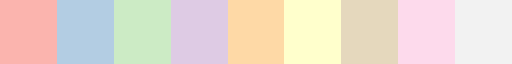

In [13]:
cmap = plt.get_cmap("Pastel1")
cmap


In [14]:
def add_position_label(
    df: pd.DataFrame, vertices: list[tuple[float, float]], label_as: str
) -> None:
    if "position" not in df.columns:
        df["position"] = np.select(
            [df["extant"].astype(bool)], ["unsampled"], default="inner node"
        )
    in_shape = (
        matplotlib.path.Path(vertices).contains_points(
            np.vstack([df["row"].to_numpy(), df["col"].to_numpy()]).T
        )
        & df["extant"]
    )
    df["position"] = np.select([in_shape], [label_as], default=df["position"])


### Outlier CA

The outlier pattern is a square, tilted about 17.6 degrees off the grid axes, with a detached band of replicators running along one side.

- **Border**: that band. Its depth stays close to 200 cells as the pattern grows, so rather than scaling up the reference polygon (which would take in part of the interior), the region is laid `OUTLIER_BORDER_DEPTH` cells deep behind the front.
- **Middle**: the reference polygon, scaled about the seed in proportion to run length.


In [15]:
REFERENCE_MIDDLE_SAMPLE = [(1600, 525), (1900, 625), (1475, 1800), (1175, 1700)]
OUTLIER_TILT = np.arctan2(1650, 5200)  # angle of border band off row axis
OUTLIER_BORDER_DEPTH = 210  # cells


def make_outlier_regions(df: pd.DataFrame) -> dict:
    center = np.array(df.attrs["seed_center"])
    factor = df.attrs["num_steps"] / REFERENCE_NUM_STEPS

    # unit vectors, as (row, col), along and across the border band
    along = np.array([np.cos(OUTLIER_TILT), np.sin(OUTLIER_TILT)])
    across = np.array([-np.sin(OUTLIER_TILT), np.cos(OUTLIER_TILT)])
    extant = df.loc[df["extant"], ["row", "col"]].to_numpy() - center
    front = (extant @ across).min()
    half_length = 1.5 * np.abs(extant @ along).max()
    border = [
        center + u * along + v * across
        for u, v in (
            (-half_length, front - 1),
            (half_length, front - 1),
            (half_length, front + OUTLIER_BORDER_DEPTH),
            (-half_length, front + OUTLIER_BORDER_DEPTH),
        )
    ]

    reference_center = (REFERENCE_GRID_SIZE - 1) / 2
    middle = [
        center + (np.array(vertex) - reference_center) * factor
        for vertex in REFERENCE_MIDDLE_SAMPLE
    ]
    return {"sampled border": border, "sampled middle": middle}


### Control CA

The control pattern is a rounded blob without a distinct border structure, so regions are laid out to be comparable in geometry and tip count to the outlier's.

- **Border**: cells within 8% of the front radius of the front, over a 150 degree arc (the outlier border is about 7.5% of the front distance deep).
- **Middle**: a rectangular strip through the center, perpendicular to the middle of the border arc.


In [16]:
CONTROL_BORDER_DEPTH_FRAC = 0.08
CONTROL_BORDER_HALF_ARC = np.deg2rad(75)
CONTROL_MIDDLE_HALF_EXTENT_FRAC = (0.2, 0.6)  # (rows, cols)


def make_control_regions(df: pd.DataFrame) -> dict:
    extant = df.loc[df["extant"], ["row", "col"]].to_numpy()
    center = extant.mean(axis=0)
    drow, dcol = (extant - center).T
    angle = np.arctan2(drow, -dcol)  # zero is toward low col
    radius = np.hypot(drow, dcol)

    # trace front over arc
    edges = np.linspace(-CONTROL_BORDER_HALF_ARC, CONTROL_BORDER_HALF_ARC, 121)
    bins = np.digitize(angle, edges) - 1
    in_arc = (bins >= 0) & (bins < len(edges) - 1)
    front = np.zeros(len(edges) - 1)
    np.maximum.at(front, bins[in_arc], radius[in_arc])
    front_radius = front.mean()
    depth = CONTROL_BORDER_DEPTH_FRAC * front_radius

    def trace(radii: np.ndarray) -> list:
        mids = (edges[:-1] + edges[1:]) / 2
        return [
            center + r * np.array([np.sin(a), -np.cos(a)])
            for a, r in zip(mids, radii)
        ]

    border = trace(front + 1) + trace(front - depth)[::-1]

    half_rows, half_cols = (
        np.array(CONTROL_MIDDLE_HALF_EXTENT_FRAC) * front_radius
    )
    middle = [
        center + np.array(offset)
        for offset in (
            (-half_rows, -half_cols),
            (-half_rows, half_cols),
            (half_rows, half_cols),
            (half_rows, -half_cols),
        )
    ]
    return {"sampled border": border, "sampled middle": middle}


In [17]:
regions = {
    "outlier": make_outlier_regions(phylos["outlier"]),
    "control": make_control_regions(phylos["control"]),
}
for name, df in phylos.items():
    for label, vertices in regions[name].items():
        add_position_label(df, vertices, label)

pd.DataFrame(
    {name: df["position"].value_counts() for name, df in phylos.items()},
)


,outlier,control
position,,
inner node,4343,39834
sampled border,27616,34582
sampled middle,83799,85782
unsampled,478695,460092


## Analysis

Ported from the reference notebook, with the phylogeny and cutoff times passed in as arguments.


In [18]:
def plot_regions(df: pd.DataFrame, ax=None):
    ax = sns.scatterplot(
        data=df[df["extant"]],
        x="col",
        y="row",
        s=0.5 / SCALE,
        linewidth=0,
        palette={
            "sampled border": cmap.colors[0],
            "sampled middle": cmap.colors[1],
            "unsampled": cmap.colors[-3],
        },
        hue="position",
        hue_order=["sampled border", "sampled middle", "unsampled"],
        rasterized=True,
        ax=ax,
    )
    ax.set_aspect("equal")
    ax.legend(title="position", markerscale=5 * SCALE)
    return ax


In [19]:
def plot(
    df: pd.DataFrame,
    color_by: typing.Optional[str] = None,
    scatter_kws: dict = {},
    tree_kws: dict = {},
    **kwargs,
):
    return draw_scatter_tree(
        df,
        hue=color_by,
        scatter_kws=dict(
            alpha=0.8,
            edgecolor="none",
            legend=True,
        )
        | scatter_kws,
        scatter_shuffle=1,
        tree_kws=dict(
            edge=dict(
                color="gainsboro",
                linewidth=0.5,
            ),
            margins=-0.05,
            layout_angular=True,
        )
        | tree_kws,
        **kwargs,
    )


In [20]:
def get_cutoff_times(df: pd.DataFrame) -> tuple[float, float]:
    num_steps = df.attrs["num_steps"]
    return COLLESS_CUTOFF_FRAC * num_steps, DELTA_CUTOFF_FRAC * num_steps


def plot_colless_index_trees(input_df: pd.DataFrame, key: str, input_ax=None):
    colless_cutoff_time, __ = get_cutoff_times(input_df)
    df = input_df.copy()
    df["extant"] = df["position"] == key
    df = pfl.alifestd_prune_extinct_lineages_asexual(df)
    df = df[df["origin_time"] < colless_cutoff_time]
    df[key] = df["extant"]
    color = cmap.colors[0] if key == "sampled border" else cmap.colors[1]
    ax = plot(
        df,
        color_by=key,
        tree_kws={"edge": {"color": [color]}},
        scatter_kws={"palette": [color]},
        ax=input_ax,
    )
    ax.get_legend().remove()


In [21]:
TREE_GENERATORS = (pfl.alifestd_make_edge_split, pfl.alifestd_make_leaf_split)


def sample_colless_index_data(input_df: pd.DataFrame, n_samples: int):
    colless_cutoff_time, __ = get_cutoff_times(input_df)
    data = {
        key: {"source": [], "colless_index": []}
        for key in ("sampled border", "sampled middle")
    }
    observed = {}
    leaf_node_counts = {}

    for key in "sampled border", "sampled middle":
        df = input_df.copy()
        df["extant"] = df["position"] == key
        df = pfl.alifestd_prune_extinct_lineages_asexual(df)
        df = pfl.alifestd_collapse_unifurcations(df)
        df = df[df["origin_time"] < colless_cutoff_time]
        df = pfl.alifestd_mark_colless_like_index_mdm_asexual(df)
        observed[key] = df["colless_like_index_mdm"].iloc[0]
        leaf_node_count = pfl.alifestd_count_leaf_nodes(df)
        leaf_node_counts[key] = leaf_node_count
        for _ in tqdm(
            range(n_samples),
            desc=f"sampling trees for {key=}",
            mininterval=30,
        ):
            for f in TREE_GENERATORS:
                tree = f(leaf_node_count)
                tree = pfl.alifestd_mark_colless_like_index_mdm_asexual(tree)
                data[key]["source"].append(
                    f.__name__.removeprefix("alifestd_make_")
                )
                data[key]["colless_index"].append(
                    tree["colless_like_index_mdm"].iloc[0]
                )

    return data, observed, leaf_node_counts


In [22]:
def plot_colless_index_data(
    sampled: dict, observed: dict, key: str, input_ax=None
):
    COLOR = "#464c5e"
    OBSERVED_COL_NAME = "observed"

    df = pd.DataFrame(sampled[key])
    lower_bound = df["colless_index"].max()
    upper_bound = df["colless_index"].min()
    for f in TREE_GENERATORS:
        real_name = f.__name__.removeprefix("alifestd_make_")
        lower_bound = min(
            lower_bound,
            df[df["source"] == real_name]["colless_index"].quantile(0.025),
        )
        upper_bound = max(
            upper_bound,
            df[df["source"] == real_name]["colless_index"].quantile(0.975),
        )
    color = cmap.colors[0] if key == "sampled border" else cmap.colors[1]
    ax = sns.boxplot(
        data=df,
        x="source",
        y="colless_index",
        showfliers=False,
        width=0.2,
        order=("leaf_split", "edge_split", OBSERVED_COL_NAME),
        boxprops={"facecolor": COLOR, "edgecolor": COLOR},
        whiskerprops={"color": COLOR},
        medianprops={"color": COLOR},
        capprops={"linewidth": 0},
        ax=input_ax,
    )
    ax = sns.scatterplot(
        data=pd.DataFrame(
            {
                "colless_index": [observed[key]],
                "source": [OBSERVED_COL_NAME],
            }
        ),
        x="source",
        y="colless_index",
        color=color,
        ax=ax,
    )
    y_max = ax.get_ylim()[1]
    ax.set_ylim([0, y_max * 1.25])
    ax.axhspan(lower_bound, upper_bound, color=f"{COLOR}20")
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")
    return ax


In [23]:
def prep_origin_time_delta(input_df: pd.DataFrame) -> pd.DataFrame:
    colless_cutoff_time, __ = get_cutoff_times(input_df)
    dfs = [
        input_df.assign(extant=input_df["position"] == key).pipe(
            pfl.alifestd_prune_extinct_lineages_asexual
        )
        for key in ("sampled border", "sampled middle")
    ]
    cutout_dfs = [
        df[(df["origin_time"] < colless_cutoff_time)]
        .pipe(pfl.alifestd_collapse_unifurcations)
        .pipe(pfl.alifestd_mark_origin_time_delta_asexual)
        for df in dfs
    ]
    return (
        pd.concat(cutout_dfs, keys=["border", "middle"])
        .reset_index(level=0)
        .rename(columns={"level_0": "source"})
    )


def plot_origin_time_delta(input_df: pd.DataFrame, input_ax=None):
    __, delta_cutoff_time = get_cutoff_times(input_df)
    df = prep_origin_time_delta(input_df)
    original_df = df.copy()
    for src in ("border", "middle"):
        original_df[f"{src}_marker_type"] = "."
        original_df[f"{src}_hue"] = "#ffffff"
    markers = "osDv"

    for i, src in enumerate(("border", "middle")):
        for j, m in enumerate(markers):
            plot_df = df[
                (df["source"] == src) & (df["origin_time"] < delta_cutoff_time)
            ].copy()
            plot_df["marker_col"] = range(len(plot_df))
            plot_df.loc[
                plot_df["marker_col"] % len(markers) != j, "origin_time"
            ] = 1e10
            origin_times = sorted(plot_df["origin_time"].unique())
            colors = sns.dark_palette(
                cmap.colors[i], n_colors=len(origin_times)
            )[1:] + [(0, 0, 0, 0)]
            for id in plot_df[plot_df["marker_col"] % len(markers) == j]["id"]:
                is_id = original_df["id"] == id
                original_df.loc[is_id, f"{src}_marker_type"] = m
                color_to_be_plotted = colors[
                    origin_times.index(
                        original_df.loc[is_id, "origin_time"].values[0]
                    )
                ]
                original_df.loc[is_id, f"{src}_hue"] = mpl.colors.rgb2hex(
                    color_to_be_plotted
                )
            ax = sns.swarmplot(
                data=plot_df,
                y="origin_time_delta",
                x="source",
                hue="origin_time",
                palette=colors,
                order=("border", "middle"),
                legend=False,
                marker=m,
                ax=input_ax,
            )

    ax.tick_params(
        axis="y",
        which="both",
        labelleft=False,
        left=False,
        labelright=True,
        right=True,
    )
    ax.yaxis.set_label_position("right")
    return original_df, ax


In [24]:
def plot_origin_time_delta_trees(
    input_df: pd.DataFrame, marker_info_df: pd.DataFrame, key: str, input_ax=None
):
    colless_cutoff_time, __ = get_cutoff_times(input_df)
    df = input_df.copy()
    df["extant"] = df["position"] == key
    df = pfl.alifestd_prune_extinct_lineages_asexual(df)
    df = df[df["origin_time"] < colless_cutoff_time]
    df = pfl.alifestd_collapse_unifurcations(df)

    src = key[-6:]
    color = cmap.colors[0] if src == "border" else cmap.colors[1]
    is_src = marker_info_df["source"] == src
    markers = list(marker_info_df[is_src][f"{src}_marker_type"])
    palette = list(marker_info_df[is_src][f"{src}_hue"])

    return plot(
        df,
        "id",
        tree_kws={
            "edge": {
                "color": [color],
                "linewidth": 0.01,
            }
        },
        scatter_kws={"markers": markers, "palette": palette, "legend": False},
        collapse_unifurcations=False,
        style="id",
        ax=input_ax,
    )


### Figure assembly


In [25]:
null_samples = {}


def show_regions(name: str) -> None:
    with tp.teed(
        plot_regions,
        phylos[name],
        teeplot_outattrs={"ca": name},
        teeplot_subdir=teeplot_subdir,
    ):
        ...


def show_colless(name: str) -> None:
    with tp.teed(
        plt.subplots,
        2,
        2,
        tight_layout=True,
        figsize=(5, 5),
        gridspec_kw={"width_ratios": [1, 1.3]},
        teeplot_outattrs={"ca": name, "viz": "plot_colless_data"},
        teeplot_subdir=teeplot_subdir,
    ) as (fig, axes):
        df = phylos[name]
        plot_colless_index_trees(df, "sampled border", axes[0][0])
        plot_colless_index_trees(df, "sampled middle", axes[1][0])
        null_samples[name] = sample_colless_index_data(df, N_NULL_SAMPLES)
        sampled, observed, __ = null_samples[name]
        plot_colless_index_data(sampled, observed, "sampled border", axes[0][1])
        axes[0][1].set_xlabel(None)
        axes[0][1].set_xticks([])
        plot_colless_index_data(sampled, observed, "sampled middle", axes[1][1])


def show_branch_lengths(name: str) -> None:
    with tp.teed(
        plt.subplot_mosaic,
        [["border", "wait_times"], ["middle", "wait_times"]],
        tight_layout=True,
        figsize=(5, 5),
        gridspec_kw={"width_ratios": [1, 1.5]},
        teeplot_outattrs={"ca": name, "viz": "plot_branch_length_data"},
        teeplot_subdir=teeplot_subdir,
    ) as (fig, axes):
        df = phylos[name]
        marker_info_df, __ = plot_origin_time_delta(df, axes["wait_times"])
        plot_origin_time_delta_trees(
            df, marker_info_df, "sampled border", axes["border"]
        )
        plot_origin_time_delta_trees(
            df, marker_info_df, "sampled middle", axes["middle"]
        )


## Outlier CA

### (a) Sampled regions

Extant cells, with those sampled for "border" (red) and "middle" (blue) highlighted.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-regions+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot-regions+ext=.png


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


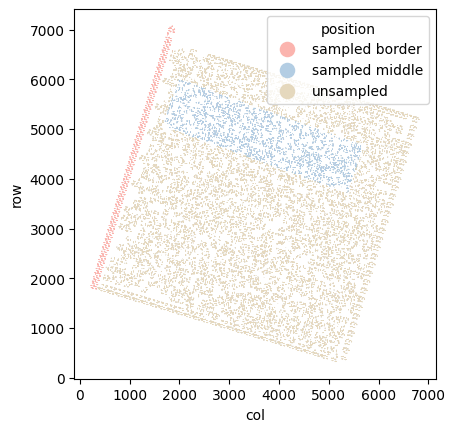

In [26]:
show_regions("outlier")


### (b) Tree imbalance

Trimmed trees for each region (left), and their Colless-like imbalance compared against random trees with the same number of leaves generated by edge splitting and leaf splitting (right).
Shaded band spans the 2.5th to 97.5th percentiles of the null models.


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:41: NumbaTypeSafetyWarning: unsafe cast from uint64 to int64. Precision may be lost.
  [reassignment[ancestor_id] for ancestor_id in ancestor_ids]
sampling trees for key='sampled middle': 100%|██████████| 10000/10000 [01:26<00:00, 115.29it/s]


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_colless_data+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_colless_data+ext=.png


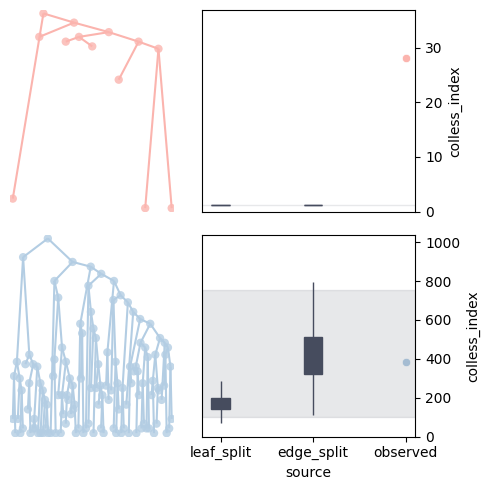

In [27]:
show_colless("outlier")


### (c) Branch lengths

Inner branch lengths of the trimmed trees (left), as a swarmplot with markers matched to tree nodes (right).


teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_branch_length_data+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=outlier+viz=plot_branch_length_data+ext=.png


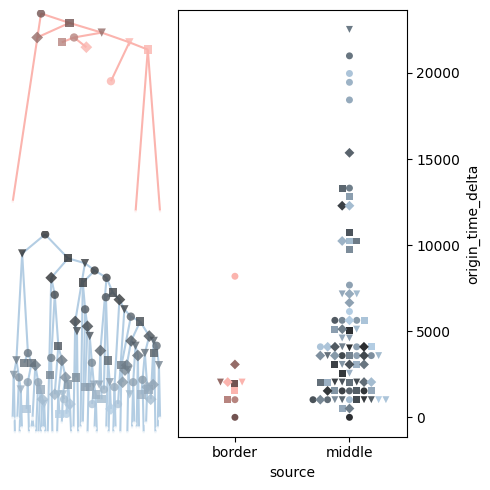

In [28]:
show_branch_lengths("outlier")


## Non-replicator control CA

### (a) Sampled regions

Extant cells, with those sampled for "border" (red) and "middle" (blue) highlighted.


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-regions+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot-regions+ext=.png


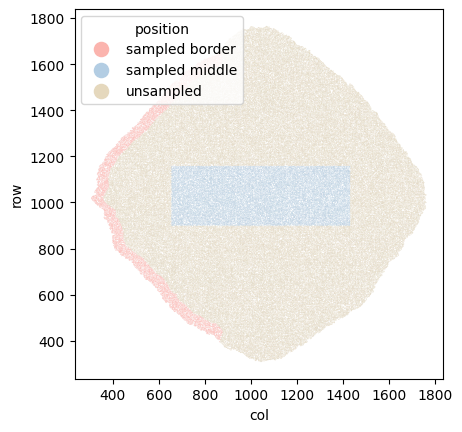

In [29]:
show_regions("control")


### (b) Tree imbalance

Trimmed trees for each region (left), and their Colless-like imbalance compared against random trees with the same number of leaves generated by edge splitting and leaf splitting (right).
Shaded band spans the 2.5th to 97.5th percentiles of the null models.


sampling trees for key='sampled middle': 100%|██████████| 10000/10000 [06:56<00:00, 24.01it/s]


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_colless_data+ext=.pdf
teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_colless_data+ext=.png


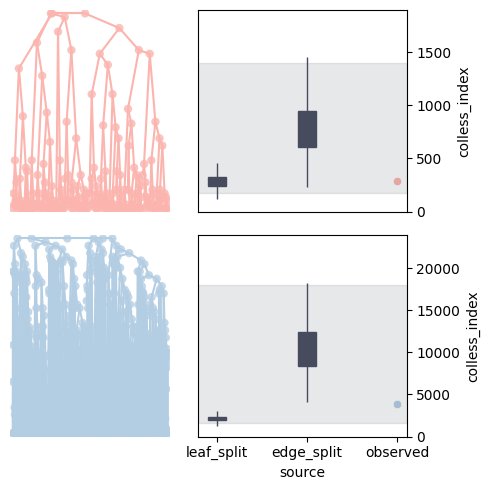

In [30]:
show_colless("control")


### (c) Branch lengths

Inner branch lengths of the trimmed trees (left), as a swarmplot with markers matched to tree nodes (right).


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 32.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 40.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 40.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 40.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_branch_length_data+ext=.pdf


/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 44.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 44.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


teeplots/2026-11-27-outlier-plots-scaled-control/ca=control+viz=plot_branch_length_data+ext=.png


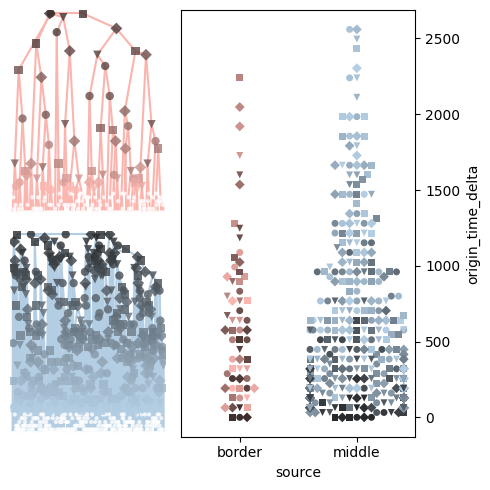

In [31]:
show_branch_lengths("control")


## Summary

Observed imbalance of each trimmed tree, and where it falls within each null model.


In [32]:
records = []
for name, (sampled, observed, leaf_node_counts) in null_samples.items():
    for key in sampled:
        null_df = pd.DataFrame(sampled[key])
        record = {
            "ca": name,
            "region": key,
            "num tips": (phylos[name]["position"] == key).sum(),
            "num trimmed tree leaves": leaf_node_counts[key],
            "observed colless": observed[key],
        }
        for source, group in null_df.groupby("source"):
            values = group["colless_index"]
            record[f"{source} null median"] = values.median()
            record[f"{source} null percentile"] = scipy_stats.percentileofscore(
                values, observed[key], kind="mean"
            )
        records.append(record)

pd.DataFrame(records).set_index(["ca", "region"]).T


ca                                outlier                       control  \
region                     sampled border sampled middle sampled border   
num tips                     27616.000000   83799.000000   34582.000000   
num trimmed tree leaves          3.000000      49.000000      71.000000   
observed colless                28.197587     383.600419     288.239404   
edge_split null median           1.275722     401.852542     752.676191   
edge_split null percentile     100.000000      44.170000       0.050000   
leaf_split null median           1.275722     169.671073     276.831751   
leaf_split null percentile     100.000000      99.970000      55.530000   

ca                                         
region                     sampled middle  
num tips                     85782.000000  
num trimmed tree leaves        356.000000  
observed colless              3863.618376  
edge_split null median       10149.647072  
edge_split null percentile       0.000000  
leaf_split null median        2126.629169  
leaf_split null percentile      99.970000

Inner branch lengths of the trimmed trees, as a fraction of run length, and a Mann-Whitney U test of border against middle.


In [33]:
records = []
for name, df in phylos.items():
    __, delta_cutoff_time = get_cutoff_times(df)
    delta_df = prep_origin_time_delta(df)
    delta_df = delta_df[delta_df["origin_time"] < delta_cutoff_time]
    delta_df = delta_df[delta_df["origin_time_delta"].notna()]
    fracs = {
        src: group["origin_time_delta"] / df.attrs["num_steps"]
        for src, group in delta_df.groupby("source")
    }
    test = scipy_stats.mannwhitneyu(fracs["border"], fracs["middle"])
    records.append(
        {
            "ca": name,
            **{f"{src} num branches": len(v) for src, v in fracs.items()},
            **{f"{src} median length": v.median() for src, v in fracs.items()},
            **{f"{src} mean length": v.mean() for src, v in fracs.items()},
            "mann-whitney u": test.statistic,
            "p": test.pvalue,
        }
    )

pd.DataFrame(records).set_index("ca").T


ca,outlier,control
border num branches,10.000000,61.000000
middle num branches,86.000000,444.000000
border median length,0.042491,0.151779
middle median length,0.075558,0.067457
border mean length,0.048436,0.172081
middle mean length,0.111924,0.129688
mann-whitney u,234.500000,16704.500000
p,0.018971,0.002989
